In [1]:
from pathlib import Path
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


ROOT = Path(os.environ.get('FISCAL_ROOT', r'C:\Users\gayeon\Dropbox\key_data\Fiscal')).expanduser()
RAW = ROOT / 'raw'
OUT = ROOT/'output'
OUT.mkdir(parents=True, exist_ok=True)
FETCH_MISSING_TBILL_FROM_FRED = True

FILE_LOG = []
def find_raw(stem, required=True):
    wanted = stem.casefold()
    hits = [p for p in RAW.iterdir() if p.is_file() and p.stem.casefold() == wanted] if RAW.exists() else []
    priority = {'.csv':0,'.xlsx':1,'.xls':2,'.txt':3}
    hits.sort(key=lambda p:priority.get(p.suffix.lower(),99))
    if not hits:
        if required:
            raise FileNotFoundError(f'Missing raw file: {stem} (.csv or .xlsx) under {RAW}')
        return None
    return hits[0]

def read_table(stem, sheet_name=0, header=0, required=True):
    p=find_raw(stem, required=required)
    if p is None: return None
    if p.suffix.lower() in ('.csv','.txt'):
        try: d=pd.read_csv(p, encoding='utf-8-sig', low_memory=False)
        except UnicodeDecodeError: d=pd.read_csv(p,encoding='cp1252',low_memory=False)
    elif p.suffix.lower() in ('.xlsx','.xls'):
        d=pd.read_excel(p, sheet_name=sheet_name, header=header)
    else:
        raise ValueError(f'Unsupported file extension: {p}')
    FILE_LOG.append({'input_stem':stem,'input_path':str(p),'rows':len(d),'columns':len(d.columns)})
    d.columns=[str(c).strip() for c in d.columns]
    return d

def dates_and_quarters(d):
    dt=next((c for c in ['observation_date','DATE','date','Date'] if c in d.columns), None)
    if dt is None: raise KeyError('Could not locate a date column: '+repr(list(d.columns)))
    d=d.copy()
    d['date']=pd.to_datetime(d[dt], errors='coerce')
    d=d.dropna(subset=['date'])
    d['quarter']=d['date'].dt.to_period('Q')
    return d

def fred_series(stem, code, outname, how='last', required=True):
    d=read_table(stem,required=required)
    if d is None: return None
    d=dates_and_quarters(d)
    if code not in d:
        raise KeyError(f'{stem}: expected FRED variable {code}; found {list(d.columns)}')
    d[outname]=pd.to_numeric(d[code].replace('.', np.nan), errors='coerce')
    
    if how=='mean':
        d=d.groupby('quarter',as_index=False)[outname].mean()
    else:
        d=d.sort_values('date').groupby('quarter',as_index=False)[outname].last()
    return d

if not RAW.exists():
    raise FileNotFoundError(RAW)


## Macro

In [2]:
ng=fred_series('bea_nominal_gdp','GDP','nominal_gdp_bn_saar')
rg=fred_series('bea_real_gdp','GDPC1','real_gdp_bn_saar')
pot=fred_series('cbo_real_potential_gdp','GDPPOT','potential_real_gdp_bn_saar')
cpi=fred_series('bea_cpi','CPIAUCSL','cpi_index',how='mean')
dff=fred_series('fed_policy_rates','DFF','effective_fed_funds_pct',how='mean')

macro=ng.merge(rg,on='quarter',how='outer').merge(pot,on='quarter',how='outer')
macro=macro.merge(cpi,on='quarter',how='outer').merge(dff,on='quarter',how='outer').sort_values('quarter')
macro['output_gap_CBO_pct']=100*(macro['real_gdp_bn_saar']/macro['potential_real_gdp_bn_saar']-1)
macro['output_gap_log_pct']=100*np.log(macro['real_gdp_bn_saar']/macro['potential_real_gdp_bn_saar'])
macro['cpi_inflation_qoq_ann_pct']=100*((macro['cpi_index']/macro['cpi_index'].shift(1))**4-1)
macro['cpi_inflation_qoq_ann_log_pct']=400*np.log(macro['cpi_index']/macro['cpi_index'].shift(1))
macro['cpi_inflation_yoy_pct']=100*(macro['cpi_index']/macro['cpi_index'].shift(4)-1)
macro['real_gdp_growth_qoq_ann_pct']=100*((macro['real_gdp_bn_saar']/macro['real_gdp_bn_saar'].shift(1))**4-1)


tbill=None
for name in ['fred_tb3ms','tbill_3m','tb3ms','bea_tbill_3m']:
    if find_raw(name,required=False) is not None:
        tbill=fred_series(name,'TB3MS','tbill_3m_pct',how='mean')
        break
if tbill is None and FETCH_MISSING_TBILL_FROM_FRED:
    try:
        import urllib.request, io
        url='https://fred.stlouisfed.org/graph/fredgraph.csv?id=TB3MS'
        with urllib.request.urlopen(url, timeout=12) as resp:
            z=pd.read_csv(io.BytesIO(resp.read()))
        z=dates_and_quarters(z)
        z['tbill_3m_pct']=pd.to_numeric(z['TB3MS'],errors='coerce')
        tbill=z.groupby('quarter',as_index=False)['tbill_3m_pct'].mean()
        z[['date','TB3MS']].to_csv(OUT/'FRED_TB3MS_download.csv',index=False)
        FILE_LOG.append({'input_stem':'TB3MS_FRED_download','input_path':url,'rows':len(z),'columns':2})
    except Exception as ex:
        print('FRED T-bill not reachable:',type(ex).__name__,str(ex)[:150])
if tbill is None:
    macro['tbill_3m_pct']=np.nan
    warnings.warn('TB3MS is missing. Add raw/tb3ms.csv or run with FRED download enabled; do not use DFF instead.')
else:
    macro=macro.merge(tbill,on='quarter',how='left')

macro=macro.drop_duplicates('quarter').sort_values('quarter').reset_index(drop=True)
assert macro['quarter'].is_unique
macro['period']=macro['quarter'].astype(str)
macro.drop(columns=['quarter']).to_csv(OUT/'macro_quarterly.csv',index=False,encoding='utf-8-sig')



## Fiscal

In [3]:
net=fred_series('bea_federal_net_lending','AD02RC1Q027SBEA','federal_net_lending_bn_saar')
interest=fred_series('bea_federal_interest_payments','A091RC1Q027SBEA','federal_interest_payments_bn_saar')
bea=ng.merge(net,on='quarter',how='outer').merge(interest,on='quarter',how='outer')
bea['primary_surplus_bn_saar']=bea['federal_net_lending_bn_saar']+bea['federal_interest_payments_bn_saar']
bea['primary_deficit_bn_saar']=-bea['primary_surplus_bn_saar']
bea['surplus_pct_GDP_ann']=100*bea['primary_surplus_bn_saar']/bea['nominal_gdp_bn_saar']

# Dallas Fed file contains a two-line header on sheet "data".
p=find_raw('dallas_govdebt')
if p.suffix.lower() in ('.xls','.xlsx'):
    dallas=pd.read_excel(p,sheet_name='data',header=[1,2])
    if len(dallas.columns)!=7:
        raise ValueError(f'Dallas Fed expected 7 columns; found {len(dallas.columns)}: {list(dallas.columns)}')
    dallas.columns=['date','par_gross_debt_bn','par_private_debt_bn','par_marketable_debt_bn',
                    'mv_gross_debt_bn','mv_private_debt_bn','mv_marketable_debt_bn']
else:
    dallas=pd.read_csv(p)
    expected=['date','par_gross_debt_bn','par_private_debt_bn','par_marketable_debt_bn',
             'mv_gross_debt_bn','mv_private_debt_bn','mv_marketable_debt_bn']
    if not set(expected).issubset(dallas.columns):
        if len(dallas.columns)==7: dallas.columns=expected
        else: raise ValueError('Dallas Fed CSV columns unrecognized. Inspect raw data headers.')
dallas=dates_and_quarters(dallas)
for c in dallas.columns:
    if c.endswith('_bn'): dallas[c]=pd.to_numeric(dallas[c],errors='coerce')
dallas=dallas.sort_values('date').groupby('quarter',as_index=False).tail(1)
dallas=dallas.drop(columns=['date']).drop_duplicates('quarter')

fiscal=bea.merge(dallas,on='quarter',how='left').sort_values('quarter')
for cat in ['gross','private','marketable']:
    fiscal[f'mv_{cat}_debt_pct_GDP']=100*fiscal[f'mv_{cat}_debt_bn']/fiscal['nominal_gdp_bn_saar']
fiscal['surplus_pct_debt_MV_quarterly']=100*(fiscal['primary_surplus_bn_saar']/4)/fiscal['mv_private_debt_bn']
fiscal['surplus_pct_debt_MV_annualized']=100*fiscal['primary_surplus_bn_saar']/fiscal['mv_private_debt_bn']
fiscal['mv_private_to_par_private']=fiscal['mv_private_debt_bn']/fiscal['par_private_debt_bn']
fiscal['period']=fiscal['quarter'].astype(str)
fiscal.drop(columns='quarter').to_csv(OUT/'fiscal_quarterly.csv',index=False,encoding='utf-8-sig')
assert fiscal['quarter'].is_unique



## SPF

In [4]:
def spf_period(d):
    d=d.copy()
    d.columns=[str(c).strip() for c in d.columns]
    y=next((c for c in d if c.upper()=='YEAR'),None)
    q=next((c for c in d if c.upper()=='QUARTER'),None)
    if not (y and q): raise KeyError('SPF workbook needs YEAR and QUARTER columns: '+repr(list(d.columns)[:12]))
    yy=pd.to_numeric(d[y],errors='coerce'); qq=pd.to_numeric(d[q],errors='coerce')
    d=d[(yy.between(1900,2100))&(qq.between(1,4))].copy()
    d['quarter']=pd.PeriodIndex(d[y].astype(int).astype(str)+'Q'+d[q].astype(int).astype(str),freq='Q')
    return d

spf=pd.DataFrame({'quarter':pd.period_range('1970Q1','2008Q3',freq='Q')})
for col in ['spf_CPI_1q_ahead_pct','spf_TBILL_1q_ahead_pct','spf_CPI_10yr_pct','spf_TBILL_10yr_pct']:
    spf[col]=np.nan

p=find_raw('spf_mean_level',required=False)
if p and p.suffix.lower() in ('.xlsx','.xls'):
    sheets=pd.ExcelFile(p).sheet_names
    for variable in ['CPI','TBILL']:
        if variable not in sheets: continue
        d=spf_period(pd.read_excel(p,sheet_name=variable))
        if variable=='CPI' and {'CPI1','CPI2'}.issubset(d):
            ratio=pd.to_numeric(d['CPI2'],errors='coerce')/pd.to_numeric(d['CPI1'],errors='coerce')
            d['spf_CPI_1q_ahead_pct']=100*(ratio**4-1)
            spf=spf.drop(columns='spf_CPI_1q_ahead_pct').merge(d[['quarter','spf_CPI_1q_ahead_pct']],on='quarter',how='left',validate='one_to_one')
        if variable=='TBILL' and 'TBILL2' in d:
            d['spf_TBILL_1q_ahead_pct']=pd.to_numeric(d['TBILL2'],errors='coerce')
            spf=spf.drop(columns='spf_TBILL_1q_ahead_pct').merge(d[['quarter','spf_TBILL_1q_ahead_pct']],on='quarter',how='left',validate='one_to_one')
    FILE_LOG.append({'input_stem':'spf_mean_level','input_path':str(p),'rows':'multiple sheets','columns':len(sheets)})
else:
    print('SPF mean-level Excel source not found; short-run SPF expectations remain missing.')

p=find_raw('spf_inflation_short_long',required=False)
if p and p.suffix.lower() in ('.xls','.xlsx'):
    infl=spf_period(pd.read_excel(p,sheet_name='INFLATION'))
    if 'INFCPI10YR' in infl:
        infl['spf_CPI_10yr_pct']=pd.to_numeric(infl['INFCPI10YR'],errors='coerce')
        spf=spf.drop(columns='spf_CPI_10yr_pct').merge(infl[['quarter','spf_CPI_10yr_pct']],on='quarter',how='left',validate='one_to_one')
    else:
        print('No INFCPI10YR in inflation workbook. Columns:',list(infl.columns)[:30])
    for ten_year_name in ['TBILL10YR','TBILL_10YR','TBILL10Y','TBILL_10Y','TBILL_LONG10YR']:
        if ten_year_name in infl:
            infl['spf_TBILL_10yr_pct']=pd.to_numeric(infl[ten_year_name],errors='coerce')
            spf=spf.drop(columns='spf_TBILL_10yr_pct').merge(infl[['quarter','spf_TBILL_10yr_pct']],on='quarter',how='left',validate='one_to_one')
            break
    FILE_LOG.append({'input_stem':'spf_inflation_short_long','input_path':str(p),'rows':len(infl),'columns':len(infl.columns)})
else:
    print('SPF inflation short/long source absent; long-run CPI expectations remain missing.')

spf['period']=spf['quarter'].astype(str)
spf.drop(columns='quarter').to_csv(OUT/'spf_expectations_quarterly.csv',index=False,encoding='utf-8-sig')



C:\Users\gayeon\anaconda3\Lib\site-packages\openpyxl\worksheet\header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")
C:\Users\gayeon\anaconda3\Lib\site-packages\openpyxl\worksheet\header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")
C:\Users\gayeon\anaconda3\Lib\site-packages\openpyxl\worksheet\header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


## 최종 패널

In [9]:
tgt=pd.DataFrame({'quarter':pd.period_range('1970Q1','2008Q3',freq='Q')})
tgt=tgt.merge(macro.drop(columns='period'),on='quarter',how='left',validate='one_to_one')
tgt=tgt.merge(fiscal.drop(columns='period',errors='ignore'),on='quarter',how='left',validate='one_to_one',suffixes=('','_fiscal'))
tgt=tgt.merge(spf.drop(columns='period'),on='quarter',how='left',validate='one_to_one')
tgt['period']=tgt['quarter'].astype(str)
model9=['output_gap_CBO_pct','cpi_inflation_qoq_ann_pct','tbill_3m_pct',
        'surplus_pct_debt_MV_quarterly','mv_private_debt_pct_GDP',
        'spf_CPI_1q_ahead_pct','spf_TBILL_1q_ahead_pct','spf_CPI_10yr_pct','spf_TBILL_10yr_pct']
assert len(tgt)==155 and tgt['quarter'].is_unique
assert all(c in tgt.columns for c in model9)
if tgt[['real_gdp_bn_saar','potential_real_gdp_bn_saar']].dropna().shape[0]>0:
    test=tgt.dropna(subset=['real_gdp_bn_saar','potential_real_gdp_bn_saar'])
    assert np.allclose(test['output_gap_CBO_pct'], 100*(test['real_gdp_bn_saar']/test['potential_real_gdp_bn_saar']-1))
if tgt['output_gap_CBO_pct'].dropna().abs().max()>25:
    warnings.warn('CBO gap exceeds 25pp. Verify GDP vs GDPPOT unit/base-year consistency.')

first=['period']+model9
other=[c for c in tgt.columns if c not in first+['quarter']]
tgt[first+other].to_csv(OUT/'1970Q1_2008Q3.csv',index=False,encoding='utf-8-sig')
audit=pd.DataFrame([{'variable':v,'nonmissing':int(tgt[v].notna().sum()),'total':len(tgt),
                     'coverage_pct':round(100*tgt[v].notna().mean(),1),
                     'first_valid':str(tgt.loc[tgt[v].notna(),'quarter'].iloc[0]) if tgt[v].notna().any() else '',
                     'last_valid':str(tgt.loc[tgt[v].notna(),'quarter'].iloc[-1]) if tgt[v].notna().any() else ''}
                    for v in model9])
audit.to_csv(OUT/'data_audit.csv',index=False,encoding='utf-8-sig')
pd.DataFrame(FILE_LOG).to_csv(OUT/'source_manifest.csv',index=False,encoding='utf-8-sig')
print(audit.to_string(index=False))
print('All 9 series complete:', bool(tgt[model9].notna().all().all()))



                     variable  nonmissing  total  coverage_pct first_valid last_valid
           output_gap_CBO_pct         155    155         100.0      1970Q1     2008Q3
    cpi_inflation_qoq_ann_pct         155    155         100.0      1970Q1     2008Q3
                 tbill_3m_pct         155    155         100.0      1970Q1     2008Q3
surplus_pct_debt_MV_quarterly         155    155         100.0      1970Q1     2008Q3
      mv_private_debt_pct_GDP         155    155         100.0      1970Q1     2008Q3
         spf_CPI_1q_ahead_pct         109    155          70.3      1981Q3     2008Q3
       spf_TBILL_1q_ahead_pct         109    155          70.3      1981Q3     2008Q3
             spf_CPI_10yr_pct          68    155          43.9      1991Q4     2008Q3
           spf_TBILL_10yr_pct           0    155           0.0                       
All 9 series complete: False


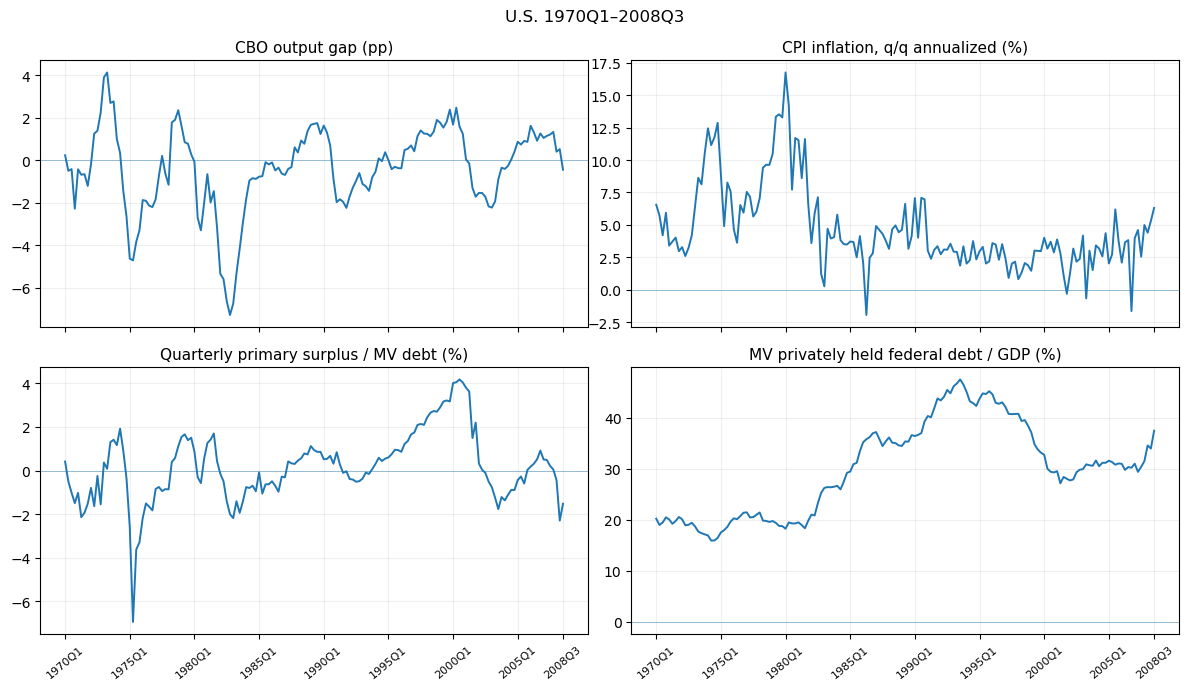

In [10]:
fig,axs=plt.subplots(2,2,figsize=(12,7),sharex=True)
series=[('output_gap_CBO_pct','CBO output gap (pp)'),('cpi_inflation_qoq_ann_pct','CPI inflation, q/q annualized (%)'),
        ('surplus_pct_debt_MV_quarterly','Quarterly primary surplus / MV debt (%)'),('mv_private_debt_pct_GDP','MV privately held federal debt / GDP (%)')]
xx=np.arange(len(tgt)); ticks=list(range(0,len(tgt),20))+[len(tgt)-1]
for ax,(col,label) in zip(axs.flat,series):
    ax.plot(xx,tgt[col].to_numpy(dtype=float),linewidth=1.4)
    ax.axhline(0,linewidth=.6,alpha=.5)
    ax.set_title(label,fontsize=11)
    ax.set_xticks(ticks)
    ax.set_xticklabels([tgt.iloc[i]['period'] for i in ticks],rotation=40,fontsize=8)
    ax.grid(alpha=.2)
fig.suptitle('U.S. 1970Q1–2008Q3')
fig.tight_layout()
plt.show()
